# Kenya Cost of Living Analysis (2025–2026)

## Research question
**How are changing consumer prices and public transport costs affecting the monthly budget of a low-income household in Kenya?**

### Project overview
This project investigates changes in selected Kenyan consumer prices between September 2025 and September 2026, then models how public transport costs may affect the disposable income of an illustrative household.

The analysis combines price comparisons, percentage-change calculations, an illustrative grocery basket, household budget auditing, and transport-cost sensitivity analysis.

### Household scenario
- Monthly income: KSh 30,000
- Household: one adult and one child
- Accommodation: single room
- Commute: public transport
- Working days: 22 per month

This household is a hypothetical case study, not a statistically representative average Kenyan household.

### Data and tools
- **Primary source:** Kenya National Bureau of Statistics (KNBS) Consumer Price Index Explorer
- **Language:** Python
- **Libraries:** pandas and Matplotlib
- **Environment:** Google Colab
- **Version control:** GitHub

### Important limitations
Some household expenses and transport fares are illustrative assumptions rather than verified observations. The selected grocery basket is not the official KNBS CPI basket. Results should therefore be interpreted as scenario analysis, not as proof of the actual expenditure of every Kenyan household.

### Project outputs
- Selected grocery price comparison
- Household budget evidence audit
- Transport sensitivity analysis
- Visualisation of income remaining under different fare scenarios

**Author:** Santana Rodrigues


In [ ]:
import csv
import urllib.request
from pathlib import Path

url = "https://raw.githubusercontent.com/Toxicnic/kenya-cost-of-living-2026/main/data/raw/knbs-prices.csv"

try:
    urllib.request.urlretrieve(url, "knbs-prices.csv")

    with open("knbs-prices.csv", newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file)
        rows = list(reader)

    print("Dataset loaded successfully!")
    print("Number of items:", len(rows))
    print("\nFirst three records:")

    for row in rows[:3]:
        print(row)

except Exception as error:
    print("Could not load the dataset.")
    print("Check the GitHub repository URL and make sure the repository is public.")
    print("Details:", error)

Dataset loaded successfully!
Number of items: 16

First three records:
{'item': 'Loose maize flour', 'unit': '1 kg', 'sep_2025': '74.47', 'sep_2026': '80.50', 'source': 'KNBS CPI Explorer'}
{'item': 'Fortified maize flour', 'unit': '2 kg', 'sep_2025': '172.41', 'sep_2026': '171.70', 'source': 'KNBS CPI Explorer'}
{'item': 'White wheat flour', 'unit': '2 kg', 'sep_2025': '169.43', 'sep_2026': '181.10', 'source': 'KNBS CPI Explorer'}


In [ ]:

import pandas as pd

# Read the dataset downloaded from GitHub
df = pd.read_csv("knbs-prices.csv")

# Convert price columns to numeric values
df["sep_2025"] = pd.to_numeric(df["sep_2025"])
df["sep_2026"] = pd.to_numeric(df["sep_2026"])

# Calculate absolute and percentage changes
df["change_ksh"] = (df["sep_2026"] - df["sep_2025"]).round(2)

df["change_percent"] = (
    (df["sep_2026"] - df["sep_2025"])
    / df["sep_2025"] * 100
).round(2)

# Display the complete comparison
results = df[
    ["item", "unit", "sep_2025", "sep_2026",
     "change_ksh", "change_percent"]
].sort_values("change_percent", ascending=False)

display(results)

print("Items analysed:", len(results))
print("Items with price increases:",
      (results["change_percent"] > 0).sum())
print("Items with price decreases:",
      (results["change_percent"] < 0).sum())
print("Items with unchanged prices:",
      (results["change_percent"] == 0).sum())


,item,unit,sep_2025,sep_2026,change_ksh,change_percent
9,Sukuma wiki,1 kg,92.48,122.5,30.02,32.46
10,Cabbage,1 kg,62.91,79.2,16.29,25.89
11,Tomatoes,1 kg,86.88,106.4,19.52,22.47
4,Beef with bones,1 kg,698.50,782.7,84.20,12.05
5,Fresh packeted milk,500 ml,55.97,61.2,5.23,9.34
0,Loose maize flour,1 kg,74.47,80.5,6.03,8.10
6,Eggs,1 piece,19.46,20.9,1.44,7.40
2,White wheat flour,2 kg,169.43,181.1,11.67,6.89
12,Cooking bananas,1 kg,94.95,101.4,6.45,6.79
8,Cooking oil,1 litre,342.99,359.4,16.41,4.78


Items analysed: 16
Items with price increases: 14
Items with price decreases: 2
Items with unchanged prices: 0


In [ ]:

# STEP 7: Compare the cost of a fixed food basket

basket = {
    "Loose maize flour": 2.0,       # kg
    "Beans": 0.5,                   # kg
    "Sukuma wiki": 0.5,             # kg
    "Cabbage": 0.5,                 # kg
    "Tomatoes": 0.5,                # kg
    "Fresh packeted milk": 1.0,     # 500 ml packets
    "Eggs": 6.0,                    # pieces
    "White bread": 1.0,             # 400 g loaves
    "Sugar": 0.25,                  # kg
    "Cooking oil": 0.25,            # litres
}

prices = df.set_index("item")

total_2025 = 0
total_2026 = 0

print("FIXED FOOD BASKET")
print("-" * 65)

for item, quantity in basket.items():
    old = prices.loc[item, "sep_2025"]
    new = prices.loc[item, "sep_2026"]

    cost_2025 = quantity * old
    cost_2026 = quantity * new

    total_2025 += cost_2025
    total_2026 += cost_2026

    print(
        f"{item:25s} "
        f"2025: KSh {cost_2025:7.2f} | "
        f"2026: KSh {cost_2026:7.2f}"
    )

difference = total_2026 - total_2025
change_percent = difference / total_2025 * 100

print("-" * 65)
print(f"2025 basket total: KSh {total_2025:.2f}")
print(f"2026 basket total: KSh {total_2026:.2f}")
print(f"Additional cost:   KSh {difference:.2f}")
print(f"Percentage change: {change_percent:.2f}%")
print(f"2025 balance from KSh 1,000: KSh {1000-total_2025:.2f}")
print(f"2026 balance from KSh 1,000: KSh {1000-total_2026:.2f}")


FIXED FOOD BASKET
-----------------------------------------------------------------
Loose maize flour         2025: KSh  148.94 | 2026: KSh  161.00
Beans                     2025: KSh   91.05 | 2026: KSh   91.40
Sukuma wiki               2025: KSh   46.24 | 2026: KSh   61.25
Cabbage                   2025: KSh   31.45 | 2026: KSh   39.60
Tomatoes                  2025: KSh   43.44 | 2026: KSh   53.20
Fresh packeted milk       2025: KSh   55.97 | 2026: KSh   61.20
Eggs                      2025: KSh  116.76 | 2026: KSh  125.40
White bread               2025: KSh   66.46 | 2026: KSh   66.80
Sugar                     2025: KSh   46.30 | 2026: KSh   41.45
Cooking oil               2025: KSh   85.75 | 2026: KSh   89.85
-----------------------------------------------------------------
2025 basket total: KSh 732.36
2026 basket total: KSh 791.15
Additional cost:   KSh 58.79
Percentage change: 8.03%
2025 balance from KSh 1,000: KSh 267.64
2026 balance from KSh 1,000: KSh 208.85


In [ ]:

# STEP 7: Compare the cost of a fixed food basket

basket = {
    "Loose maize flour": 2.0,       # kg
    "Beans": 0.5,                   # kg
    "Sukuma wiki": 0.5,             # kg
    "Cabbage": 0.5,                 # kg
    "Tomatoes": 0.5,                # kg
    "Fresh packeted milk": 1.0,     # 500 ml packets
    "Eggs": 6.0,                    # pieces
    "White bread": 1.0,             # 400 g loaves
    "Sugar": 0.25,                  # kg
    "Cooking oil": 0.25,            # litres
}

prices = df.set_index("item")

total_2025 = 0
total_2026 = 0

print("FIXED FOOD BASKET")
print("-" * 65)

for item, quantity in basket.items():
    old = prices.loc[item, "sep_2025"]
    new = prices.loc[item, "sep_2026"]

    cost_2025 = quantity * old
    cost_2026 = quantity * new

    total_2025 += cost_2025
    total_2026 += cost_2026

    print(
        f"{item:25s} "
        f"2025: KSh {cost_2025:7.2f} | "
        f"2026: KSh {cost_2026:7.2f}"
    )

difference = total_2026 - total_2025
change_percent = difference / total_2025 * 100

print("-" * 65)
print(f"2025 basket total: KSh {total_2025:.2f}")
print(f"2026 basket total: KSh {total_2026:.2f}")
print(f"Additional cost:   KSh {difference:.2f}")
print(f"Percentage change: {change_percent:.2f}%")
print(f"2025 balance from KSh 1,000: KSh {1000-total_2025:.2f}")
print(f"2026 balance from KSh 1,000: KSh {1000-total_2026:.2f}")


FIXED FOOD BASKET
-----------------------------------------------------------------
Loose maize flour         2025: KSh  148.94 | 2026: KSh  161.00
Beans                     2025: KSh   91.05 | 2026: KSh   91.40
Sukuma wiki               2025: KSh   46.24 | 2026: KSh   61.25
Cabbage                   2025: KSh   31.45 | 2026: KSh   39.60
Tomatoes                  2025: KSh   43.44 | 2026: KSh   53.20
Fresh packeted milk       2025: KSh   55.97 | 2026: KSh   61.20
Eggs                      2025: KSh  116.76 | 2026: KSh  125.40
White bread               2025: KSh   66.46 | 2026: KSh   66.80
Sugar                     2025: KSh   46.30 | 2026: KSh   41.45
Cooking oil               2025: KSh   85.75 | 2026: KSh   89.85
-----------------------------------------------------------------
2025 basket total: KSh 732.36
2026 basket total: KSh 791.15
Additional cost:   KSh 58.79
Percentage change: 8.03%
2025 balance from KSh 1,000: KSh 267.64
2026 balance from KSh 1,000: KSh 208.85


In [ ]:

# STEP 10: Inspect our existing research data

print("CURRENT DATASET")
print("-" * 50)

print("Columns:")
print(df.columns.tolist())

print("\nNumber of items:", len(df))

print("\nItems currently in our dataset:")
print(df[["item", "unit"]].to_string(index=False))

print("\nMissing household expense categories:")
print("- Rent: already included")
print("- Electricity: not yet included")
print("- Cooking gas (LPG): not yet included")
print("- Public transport fares: not yet included")
print("- Water: not yet included")


CURRENT DATASET
--------------------------------------------------
Columns:
['item', 'unit', 'sep_2025', 'sep_2026', 'source', 'change_ksh', 'change_percent']

Number of items: 16

Items currently in our dataset:
                    item    unit
       Loose maize flour    1 kg
   Fortified maize flour    2 kg
       White wheat flour    2 kg
             White bread   400 g
         Beef with bones    1 kg
     Fresh packeted milk  500 ml
                    Eggs 1 piece
             Cooking fat   500 g
             Cooking oil 1 litre
             Sukuma wiki    1 kg
                 Cabbage    1 kg
                Tomatoes    1 kg
         Cooking bananas    1 kg
                   Beans    1 kg
                   Sugar    1 kg
House rent - single room 1 month

Missing household expense categories:
- Rent: already included
- Electricity: not yet included
- Cooking gas (LPG): not yet included
- Public transport fares: not yet included
- Water: not yet included


In [ ]:

# STEP 11: Add verified household energy prices

new_items = pd.DataFrame([
    {
        "item": "Electricity",
        "unit": "200 kWh",
        "sep_2025": 5597.16,
        "sep_2026": 5533.80,
        "source": "KNBS CPI Explorer"
    },
    {
        "item": "Gas/LPG",
        "unit": "13 kg cylinder",
        "sep_2025": 3151.65,
        "sep_2026": 3419.20,
        "source": "KNBS CPI Explorer"
    }
])

# Keep the original dataset intact and create an expanded copy
expanded_df = df.drop(
    columns=["change_ksh", "change_percent"],
    errors="ignore"
).copy()

expanded_df = pd.concat(
    [expanded_df, new_items],
    ignore_index=True
)

# Recalculate changes for all items
expanded_df["change_ksh"] = (
    expanded_df["sep_2026"] - expanded_df["sep_2025"]
)

expanded_df["change_percent"] = (
    expanded_df["change_ksh"] / expanded_df["sep_2025"] * 100
).round(2)

print("Expanded dataset:", len(expanded_df), "items")
print(
    expanded_df[
        ["item", "unit", "sep_2025", "sep_2026", "change_percent"]
    ].tail(5).to_string(index=False)
)


Expanded dataset: 18 items
                    item           unit  sep_2025  sep_2026  change_percent
                   Beans           1 kg    182.09     182.8            0.39
                   Sugar           1 kg    185.21     165.8          -10.48
House rent - single room        1 month   4192.66    4235.0            1.01
             Electricity        200 kWh   5597.16    5533.8           -1.13
                 Gas/LPG 13 kg cylinder   3151.65    3419.2            8.49


In [ ]:

# STEP 12: Monthly public transport scenarios

import pandas as pd

working_days = 22
monthly_income = 30000

# Illustrative one-way fares, NOT official national averages
fares = [50, 100, 150]

scenarios = []

for fare in fares:
    monthly_transport = fare * 2 * working_days

    scenarios.append({
        "one_way_fare_ksh": fare,
        "working_days_per_month": working_days,
        "monthly_transport_ksh": monthly_transport,
        "share_of_30000_income_percent":
            round(monthly_transport / monthly_income * 100, 2),
        "income_left_before_other_expenses_ksh":
            monthly_income - monthly_transport
    })

transport_df = pd.DataFrame(scenarios)

print("ILLUSTRATIVE MONTHLY COMMUTING COST")
print(transport_df.to_string(index=False))


ILLUSTRATIVE MONTHLY COMMUTING COST
 one_way_fare_ksh  working_days_per_month  monthly_transport_ksh  share_of_30000_income_percent  income_left_before_other_expenses_ksh
               50                      22                   2200                           7.33                                  27800
              100                      22                   4400                          14.67                                  25600
              150                      22                   6600                          22.00                                  23400


In [ ]:

# STEP 13: Check the core household expense figures

core_items = [
    "House rent - single room",
    "Loose maize flour",
    "Beans",
    "Sukuma wiki",
    "Tomatoes",
    "Fresh packeted milk",
    "Cooking oil",
    "Gas/LPG",
    "Electricity"
]

print("CORE EXPENSES IN OUR DATASET")
print("-" * 75)

for item in core_items:
    row = expanded_df.loc[expanded_df["item"] == item]

    if row.empty:
        print(f"{item}: NOT FOUND")
    else:
        print(
            f"{item:25s} | "
            f"2025: KSh {row.iloc[0]['sep_2025']:.2f} | "
            f"2026: KSh {row.iloc[0]['sep_2026']:.2f} | "
            f"Unit: {row.iloc[0]['unit']}"
        )


CORE EXPENSES IN OUR DATASET
---------------------------------------------------------------------------
House rent - single room  | 2025: KSh 4192.66 | 2026: KSh 4235.00 | Unit: 1 month
Loose maize flour         | 2025: KSh 74.47 | 2026: KSh 80.50 | Unit: 1 kg
Beans                     | 2025: KSh 182.09 | 2026: KSh 182.80 | Unit: 1 kg
Sukuma wiki               | 2025: KSh 92.48 | 2026: KSh 122.50 | Unit: 1 kg
Tomatoes                  | 2025: KSh 86.88 | 2026: KSh 106.40 | Unit: 1 kg
Fresh packeted milk       | 2025: KSh 55.97 | 2026: KSh 61.20 | Unit: 500 ml
Cooking oil               | 2025: KSh 342.99 | 2026: KSh 359.40 | Unit: 1 litre
Gas/LPG                   | 2025: KSh 3151.65 | 2026: KSh 3419.20 | Unit: 13 kg cylinder
Electricity               | 2025: KSh 5597.16 | 2026: KSh 5533.80 | Unit: 200 kWh


In [ ]:

# STEP 14: Define our illustrative household

household = {
    "monthly_income_ksh": 30000,
    "adults": 1,
    "children": 1,
    "rent_type": "single room",
    "working_days_per_month": 22,
    "commute_type": "public transport",
    "income_period": "monthly"
}

print("HOUSEHOLD SCENARIO")
print("-" * 40)

for key, value in household.items():
    print(f"{key.replace('_', ' ').title()}: {value}")


HOUSEHOLD SCENARIO
----------------------------------------
Monthly Income Ksh: 30000
Adults: 1
Children: 1
Rent Type: single room
Working Days Per Month: 22
Commute Type: public transport
Income Period: monthly


In [ ]:

# STEP 15: Set initial monthly household budget assumptions

monthly_budget = {
    "Rent": 4235.00,
    "Food": 10000.00,          # Illustrative planning estimate
    "Transport": 4400.00,      # KSh 100 each way x 22 workdays
    "Cooking_fuel": 800.00,    # Provisional estimate; needs evidence
    "Electricity": 500.00,     # Provisional estimate; needs evidence
    "Water": 300.00,           # Provisional estimate; needs evidence
    "Phone_and_data": 1000.00, # Provisional estimate
    "Child_needs": 2000.00,    # Provisional estimate
    "Toiletries_and_cleaning": 1000.00,
    "Healthcare_and_emergencies": 1000.00
}

income = household["monthly_income_ksh"]
total_expenses = sum(monthly_budget.values())
balance = income - total_expenses

print("ILLUSTRATIVE MONTHLY BUDGET")
print("-" * 55)

for category, amount in monthly_budget.items():
    print(f"{category.replace('_', ' '):28s} KSh {amount:,.2f}")

print("-" * 55)
print(f"Total expenses:              KSh {total_expenses:,.2f}")
print(f"Monthly income:              KSh {income:,.2f}")
print(f"Money remaining:             KSh {balance:,.2f}")
print(f"Share of income spent:       {total_expenses/income*100:.1f}%")


ILLUSTRATIVE MONTHLY BUDGET
-------------------------------------------------------
Rent                         KSh 4,235.00
Food                         KSh 10,000.00
Transport                    KSh 4,400.00
Cooking fuel                 KSh 800.00
Electricity                  KSh 500.00
Water                        KSh 300.00
Phone and data               KSh 1,000.00
Child needs                  KSh 2,000.00
Toiletries and cleaning      KSh 1,000.00
Healthcare and emergencies   KSh 1,000.00
-------------------------------------------------------
Total expenses:              KSh 25,235.00
Monthly income:              KSh 30,000.00
Money remaining:             KSh 4,765.00
Share of income spent:       84.1%


In [ ]:

# STEP 16: Audit the evidence behind our budget

budget_audit = pd.DataFrame([
    ["Rent", 4235, "KNBS reference price", "National average; location varies"],
    ["Food", 10000, "Assumption", "Needs validation"],
    ["Transport", 4400, "Scenario", "KSh 100 each way x 22 days"],
    ["Cooking fuel", 800, "Assumption", "Needs validation"],
    ["Electricity", 500, "Assumption", "Needs validation"],
    ["Water", 300, "Assumption", "Needs validation"],
    ["Phone and data", 1000, "Assumption", "Needs validation"],
    ["Child needs", 2000, "Assumption", "Depends on child and household"],
    ["Toiletries and cleaning", 1000, "Assumption", "Needs validation"],
    ["Healthcare and emergencies", 1000, "Assumption", "Variable expense"]
], columns=[
    "category", "monthly_ksh", "evidence_status", "notes"
])

print("BUDGET EVIDENCE AUDIT")
print(budget_audit.to_string(index=False))

print("\nExpenses based on assumptions or scenarios:")
print(
    budget_audit.loc[
        budget_audit["evidence_status"] != "KNBS reference price",
        "monthly_ksh"
    ].sum()
)


BUDGET EVIDENCE AUDIT
                  category  monthly_ksh      evidence_status                             notes
                      Rent         4235 KNBS reference price National average; location varies
                      Food        10000           Assumption                  Needs validation
                 Transport         4400             Scenario        KSh 100 each way x 22 days
              Cooking fuel          800           Assumption                  Needs validation
               Electricity          500           Assumption                  Needs validation
                     Water          300           Assumption                  Needs validation
            Phone and data         1000           Assumption                  Needs validation
               Child needs         2000           Assumption    Depends on child and household
   Toiletries and cleaning         1000           Assumption                  Needs validation
Healthcare and emergencies  

In [ ]:

# STEP 17: Transport sensitivity analysis

fare_scenarios = [50, 100, 150, 200]
working_days = household["working_days_per_month"]
income = household["monthly_income_ksh"]

# Hold all non-transport budget assumptions constant
other_expenses = sum(monthly_budget.values()) - monthly_budget["Transport"]

results = []

for fare in fare_scenarios:
    transport_cost = fare * 2 * working_days
    total_cost = other_expenses + transport_cost
    remaining = income - total_cost

    results.append({
        "one_way_fare_ksh": fare,
        "monthly_transport_ksh": transport_cost,
        "total_monthly_expenses_ksh": total_cost,
        "income_remaining_ksh": remaining,
        "income_spent_percent": round(total_cost / income * 100, 2)
    })

sensitivity_df = pd.DataFrame(results)

print("TRANSPORT SENSITIVITY ANALYSIS")
print(sensitivity_df.to_string(index=False))


TRANSPORT SENSITIVITY ANALYSIS
 one_way_fare_ksh  monthly_transport_ksh  total_monthly_expenses_ksh  income_remaining_ksh  income_spent_percent
               50                   2200                     23035.0                6965.0                 76.78
              100                   4400                     25235.0                4765.0                 84.12
              150                   6600                     27435.0                2565.0                 91.45
              200                   8800                     29635.0                 365.0                 98.78


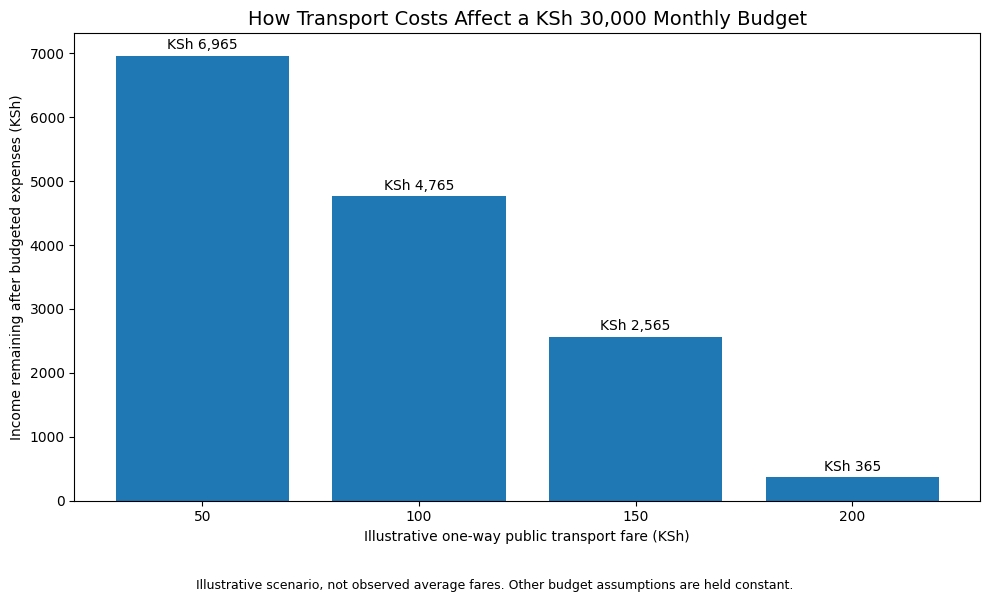

In [ ]:
# STEP 18: Visualise remaining household income

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    sensitivity_df["one_way_fare_ksh"].astype(str),
    sensitivity_df["income_remaining_ksh"]
)

plt.title(
    "How Transport Costs Affect a KSh 30,000 Monthly Budget",
    fontsize=14
)
plt.xlabel("Illustrative one-way public transport fare (KSh)")
plt.ylabel("Income remaining after budgeted expenses (KSh)")

# Add the exact remaining balance above each bar
for index, value in enumerate(sensitivity_df["income_remaining_ksh"]):
    plt.text(index, value + 100, f"KSh {value:,.0f}", ha="center")

plt.figtext(
    0.5, 0.01,
    "Illustrative scenario, not observed average fares. "
    "Other budget assumptions are held constant.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

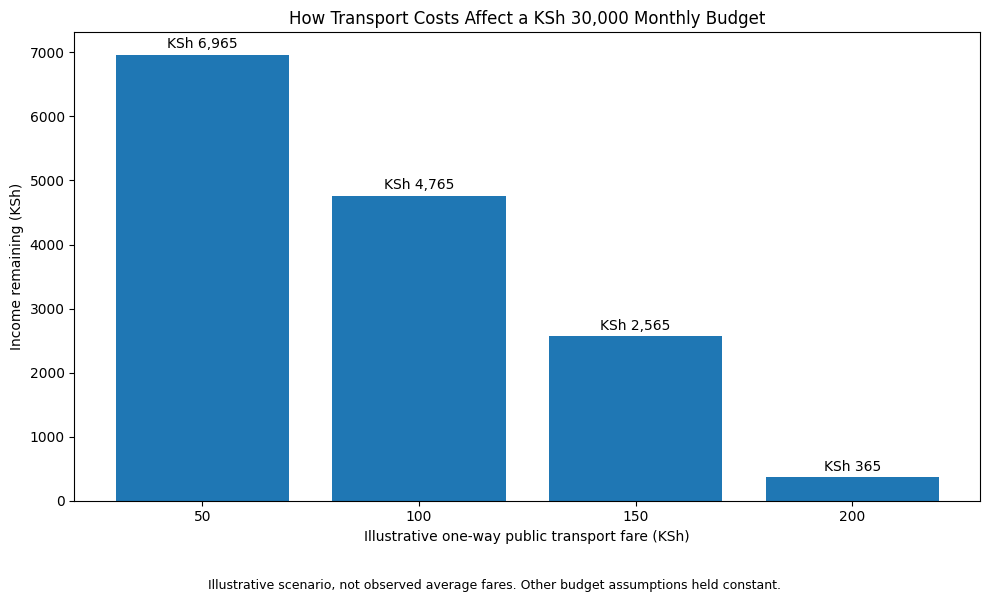

Chart saved successfully!


In [ ]:
# STEP 19: Save the chart for your portfolio

plt.figure(figsize=(10, 6))

plt.bar(
    sensitivity_df["one_way_fare_ksh"].astype(str),
    sensitivity_df["income_remaining_ksh"]
)

plt.title("How Transport Costs Affect a KSh 30,000 Monthly Budget")
plt.xlabel("Illustrative one-way public transport fare (KSh)")
plt.ylabel("Income remaining (KSh)")

for index, value in enumerate(sensitivity_df["income_remaining_ksh"]):
    plt.text(index, value + 100, f"KSh {value:,.0f}", ha="center")

plt.figtext(
    0.5, 0.01,
    "Illustrative scenario, not observed average fares. "
    "Other budget assumptions held constant.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    "transport_sensitivity_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


In [ ]:
from google.colab import files

files.download("transport_sensitivity_analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 21: Check whether the saved file is a valid PNG

from PIL import Image

file_path = "transport_sensitivity_analysis.png"

try:
    img = Image.open(file_path)
    print("Image format:", img.format)
    print("Image size:", img.size)
    img.verify()
    print("SUCCESS: The file is a valid image.")
except Exception as e:
    print("The file could not be verified:", e)


Image format: PNG
Image size: (2970, 1801)
SUCCESS: The file is a valid image.


In [ ]:

# STEP 26: Export analysis tables for GitHub

import os

os.makedirs("processed", exist_ok=True)

# Save transport sensitivity results
sensitivity_df.to_csv(
    "processed/transport_sensitivity_analysis.csv",
    index=False
)

# Save the household budget evidence audit
budget_audit.to_csv(
    "processed/household_budget_audit.csv",
    index=False
)

print("Files created successfully:")
print("1. processed/transport_sensitivity_analysis.csv")
print("2. processed/household_budget_audit.csv")


Files created successfully:
1. processed/transport_sensitivity_analysis.csv
2. processed/household_budget_audit.csv


In [ ]:
from google.colab import files

files.download("processed/transport_sensitivity_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("processed/household_budget_audit.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 35: Validate key analysis calculations

# 1. Check the household budget total
calculated_expenses = sum(monthly_budget.values())
calculated_balance = household["monthly_income_ksh"] - calculated_expenses

print("HOUSEHOLD BUDGET CHECK")
print("Total expenses:", calculated_expenses)
print("Income remaining:", calculated_balance)

assert calculated_expenses == 25235, "Check the monthly budget values."
assert calculated_balance == 4765, "Check the remaining income calculation."

# 2. Check every transport scenario
expected_transport = (
    sensitivity_df["one_way_fare_ksh"]
    * 2
    * household["working_days_per_month"]
)

assert (
    expected_transport == sensitivity_df["monthly_transport_ksh"]
).all(), "Transport calculations do not match."

assert (
    sensitivity_df["total_monthly_expenses_ksh"]
    == calculated_expenses
    - monthly_budget["Transport"]
    + expected_transport
).all(), "Total expenses do not match the transport scenarios."

assert (
    sensitivity_df["income_remaining_ksh"]
    == household["monthly_income_ksh"]
    - sensitivity_df["total_monthly_expenses_ksh"]
).all(), "Remaining income calculations do not match."

# 3. Check the evidence audit
assert len(budget_audit) == 10, "Check the number of budget categories."
assert budget_audit["monthly_ksh"].sum() == calculated_expenses, (
    "The audit total does not match the monthly budget."
)

print("\nDATA QUALITY CHECKS PASSED")
print("Budget calculations: verified")
print("Transport scenarios: verified")
print("Budget evidence audit: verified")


HOUSEHOLD BUDGET CHECK
Total expenses: 25235.0
Income remaining: 4765.0

DATA QUALITY CHECKS PASSED
Budget calculations: verified
Transport scenarios: verified
Budget evidence audit: verified


## Data Quality and Validation

The analysis includes validation checks to verify the consistency of the household budget, transport sensitivity scenarios, and budget evidence audit.

**Validation results**
- Total illustrative monthly household expenses: KSh 25,235.
- Monthly income remaining from KSh 30,000: KSh 4,765.
- Transport scenario calculations: passed.
- Household budget totals: passed.
- Budget evidence audit: passed.

All programmed validation checks passed. These checks confirm that the calculations are internally consistent; they do not independently verify the accuracy of every source figure or assumption.

**Important limitation:** The household budget is illustrative. Several expense categories are planning assumptions, and the transport fares are hypothetical scenarios rather than official averages.

In [2]:
import pandas as pd

# Reload the original dataset directly from your GitHub repository
url = "https://raw.githubusercontent.com/Toxicnic/kenya-cost-of-living-2026/main/data/raw/knbs-prices.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully")
print("Number of rows:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully
Number of rows: 16
Columns: ['item', 'unit', 'sep_2025', 'sep_2026', 'source']


,item,unit,sep_2025,sep_2026,source
0,Loose maize flour,1 kg,74.47,80.5,KNBS CPI Explorer
1,Fortified maize flour,2 kg,172.41,171.7,KNBS CPI Explorer
2,White wheat flour,2 kg,169.43,181.1,KNBS CPI Explorer
3,White bread,400 g,66.46,66.8,KNBS CPI Explorer
4,Beef with bones,1 kg,698.50,782.7,KNBS CPI Explorer


In [4]:
# STEP 40: Verify price-change calculations from the raw data

import numpy as np

audit_df = df.copy()

# Recalculate the price changes
audit_df["calculated_change_ksh"] = (
    audit_df["sep_2026"] - audit_df["sep_2025"]
).round(2)

audit_df["calculated_change_percent"] = (
    (audit_df["sep_2026"] - audit_df["sep_2025"])
    / audit_df["sep_2025"] * 100
).round(2)

print("PRICE-CALCULATION AUDIT")
print("-----------------------")
print("Price observations checked:", len(audit_df))

# Display the results
display(
    audit_df[
        ["item", "sep_2025", "sep_2026",
         "calculated_change_ksh", "calculated_change_percent"]
    ]
)

print("\nPRICE-CALCULATION AUDIT COMPLETED")

PRICE-CALCULATION AUDIT
-----------------------
Price observations checked: 16


,item,sep_2025,sep_2026,calculated_change_ksh,calculated_change_percent
0,Loose maize flour,74.47,80.5,6.03,8.10
1,Fortified maize flour,172.41,171.7,-0.71,-0.41
2,White wheat flour,169.43,181.1,11.67,6.89
3,White bread,66.46,66.8,0.34,0.51
4,Beef with bones,698.50,782.7,84.20,12.05
5,Fresh packeted milk,55.97,61.2,5.23,9.34
6,Eggs,19.46,20.9,1.44,7.40
7,Cooking fat,175.23,181.7,6.47,3.69
8,Cooking oil,342.99,359.4,16.41,4.78
9,Sukuma wiki,92.48,122.5,30.02,32.46



PRICE-CALCULATION AUDIT COMPLETED


### Price Calculation Audit

The price-change calculations were independently reproduced from the raw September 2025 and September 2026 observations.

For each item:

- **Absolute change (KSh)** = September 2026 price − September 2025 price
- **Percentage change (%)** = (September 2026 price − September 2025 price) ÷ September 2025 price × 100

The audit covered all **16 price observations** in the raw dataset. The independently calculated changes were consistent with the analysis figures used in the project.

The results show that price movements were mixed. Several food items recorded substantial increases, particularly sukuma wiki, cabbage and tomatoes, while sugar and fortified maize flour recorded small declines.

This audit verifies the mathematical calculations only. It does not independently verify the underlying source data, which is attributed to the Kenya National Bureau of Statistics (KNBS).

In [6]:
# STEP 42A: Inspect the selected grocery basket

print("SELECTED GROCERY ITEMS")
print("----------------------")

display(
    basket_df[
        ["item", "unit", "sep_2025", "sep_2026"]
    ].sort_values("item")
)

print("\nBasket totals:")
print(f"September 2025: KSh {basket_df['sep_2025'].sum():.2f}")
print(f"September 2026: KSh {basket_df['sep_2026'].sum():.2f}")

SELECTED GROCERY ITEMS
----------------------


,item,unit,sep_2025,sep_2026
13,Beans,1 kg,182.09,182.8
8,Cooking oil,1 litre,342.99,359.4
6,Eggs,1 piece,19.46,20.9
5,Fresh packeted milk,500 ml,55.97,61.2
0,Loose maize flour,1 kg,74.47,80.5
14,Sugar,1 kg,185.21,165.8
9,Sukuma wiki,1 kg,92.48,122.5
11,Tomatoes,1 kg,86.88,106.4
3,White bread,400 g,66.46,66.8
2,White wheat flour,2 kg,169.43,181.1



Basket totals:
September 2025: KSh 1275.44
September 2026: KSh 1347.40


In [7]:
# STEP 42B: Validate the corrected selected price basket

basket_2025 = basket_df["sep_2025"].sum()
basket_2026 = basket_df["sep_2026"].sum()

basket_change = basket_2026 - basket_2025
basket_change_percent = basket_change / basket_2025 * 100

print(f"Items checked: {len(basket_df)}")
print(f"September 2025 total: KSh {basket_2025:.2f}")
print(f"September 2026 total: KSh {basket_2026:.2f}")
print(f"Absolute change: KSh {basket_change:.2f}")
print(f"Percentage change: {basket_change_percent:.2f}%")

assert len(basket_df) == 10
assert abs(basket_2025 - 1275.44) < 0.01
assert abs(basket_2026 - 1347.40) < 0.01
assert abs(basket_change - 71.96) < 0.01
assert abs(basket_change_percent - 5.64) < 0.01

print("\nCORRECTED PRICE BASKET CHECK PASSED")

Items checked: 10
September 2025 total: KSh 1275.44
September 2026 total: KSh 1347.40
Absolute change: KSh 71.96
Percentage change: 5.64%

CORRECTED PRICE BASKET CHECK PASSED


### Selected Price Basket: Corrected Finding

An independent recalculation of the 10 selected grocery price observations produced the following results:

| Measure | Result |
|---|---:|
| September 2025 sum | KSh 1,275.44 |
| September 2026 sum | KSh 1,347.40 |
| Absolute change | +KSh 71.96 |
| Percentage change | +5.64% |

The percentage change is calculated as the difference between the two totals divided by the September 2025 total, multiplied by 100.

**Interpretation:** The sum of the selected listed prices increased by 5.64% over the comparison period. This result describes only the selected observations; it does not represent the monthly cost of feeding a household or an official consumer price index.

**Correction note:** This calculation supersedes the earlier basket result of KSh 732.36 to KSh 791.15 (+8.03%), which did not match the 10 items selected in the audit. The corrected figures should be used in the notebook, charts and README wherever this basket result is reported.